In [21]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

In [22]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers
import pandas as pd

def evaluate_model(y_true, y_pred, scores):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Clf Report": clf_report.strip()
    }

    return result


In [94]:
from tensorflow.keras import layers, Model
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer.primitives import Sampler
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.optimizers import COBYLA
import matplotlib.pyplot as plt
import time

# --------------------------
# 1️⃣ Feature extraction from QAE
# --------------------------
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer.primitives import Sampler
from qiskit_machine_learning.neural_networks import SamplerQNN
from tqdm import tqdm

def get_latent_vectors(ae_circ, trained_params, weight_params, qnn, data, num_latent, num_trash, encoding_fn, num_features=8, shots=1024):
    """
    Extract latent vectors from a trained QAE for classical post-processing (NCE / Isolation Forest).

    Parameters
    ----------
    ae_circ : QuantumCircuit
        Trained autoencoder circuit.
    trained_params : list or np.ndarray
        Parameter values obtained from training (COBYLA).
    weight_params : list
        The parameters in the AE that are trainable.
    qnn : SamplerQNN
        QNN wrapper around the AE circuit.
    data : np.ndarray
        Scaled input data (shape [n_samples, n_total_features]).
    num_latent : int
        Number of latent qubits in the AE.
    num_trash : int
        Number of trash qubits in the AE.
    encoding_fn : function
        Function to encode classical data to a quantum circuit (e.g., dense_angle_encoding).
    num_features : int
        Number of classical features to select for encoding (slice of input).

    Returns
    -------
    latent_vectors : np.ndarray
        Array of shape [n_samples, num_latent] with measured probabilities from latent qubits.
    """

    total_qubits = num_latent + 2 * num_trash + 1  # latent + trash + auxiliary
    latent_vectors = []

    # Assign trained parameters
    ae_circ = ae_circ.assign_parameters({p: v for p, v in zip(weight_params, trained_params)})

    for x in tqdm(data, desc="Extracting latent vectors"):
        # 1️⃣ Slice input to match encoder input size
        input_slice = x[:num_features]  # scale already done (0, π)

        # 2️⃣ Encode input
        enc_circ = encoding_fn(input_slice)
        enc_qubits = enc_circ.num_qubits

        # 3️⃣ Compose full circuit
        full_circ = QuantumCircuit(total_qubits, num_latent)  # measure latent qubits
        full_circ.compose(enc_circ, qubits=range(enc_qubits), inplace=True)
        full_circ.compose(ae_circ, inplace=True)

        # 4️⃣ Measure latent qubits
        # for i in range(num_latent):
        #     full_circ.measure(i, i)

        # # 5️⃣ Run circuit
        # job = qnn.sampler.run([full_circ])
        # result = job.result()
        # quasi = result.quasi_dists[0]

        # # 6️⃣ Compute classical probabilities for latent qubits
        # p_vector = np.zeros(num_latent)
        # for bitint, prob in quasi.items():
        #     # Convert integer to binary string, padded to num_latent
        #     bits = np.array([int(b) for b in format(bitint, f'0{num_latent}b')])
        #     p_vector += bits * prob  # expected value per qubit
        
        # latent_vectors.append(p_vector)
        exp_vals = []
        for basis in ["Z", "X", "Y"]:
            circ = full_circ.copy()
            for i in range(num_latent):
                if basis == "X":
                    circ.h(i)  # rotate X -> Z
                elif basis == "Y":
                    circ.sdg(i)
                    circ.h(i)  # rotate Y -> Z
            circ.measure(range(num_latent), range(num_latent))
            
            job = qnn.sampler.run([circ], shots=shots)
            result = job.result()
            counts = result.quasi_dists[0]  # dictionary of bitstring -> prob
            
            # Convert counts to expectation value per qubit
            ev = np.zeros(num_latent)
            for bitstring, prob in counts.items():
                bits = np.array([int(b) for b in format(bitstring, f'0{num_latent}b')])
                ev += (1 - 2*bits) * prob  # |0> → +1, |1> → -1

            exp_vals.extend(ev)

        latent_vectors.append(exp_vals)

    return np.array(latent_vectors)


# Noise generation function for NCE
def generate_nce_noise(X, noise_ratio=1.0, perturb_std=0.5):
    """
    Generate negative samples for NCE training.
    Combines feature shuffling and Gaussian perturbation.
    
    Args:
        X: np.ndarray of normal samples
        noise_ratio: multiplier for how many noise samples to generate vs normal
        perturb_std: scaling factor for Gaussian noise
    Returns:
        np.ndarray of synthetic anomalies
    """
    n_samples = int(len(X) * noise_ratio)
    noise = np.copy(X[np.random.choice(len(X), n_samples, replace=True)])

    # Step 1: Feature shuffle (destroys correlations)
    for col in range(noise.shape[1]):
        np.random.shuffle(noise[:, col])

    # Step 2: Gaussian perturbation
    col_std = np.std(X, axis=0)
    noise += np.random.normal(0, perturb_std * col_std, size=noise.shape)

    return noise

In [95]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [96]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

reduced_testing_data = testing_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)

reduced_normal_training_data = normal_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)

reduced_anomalous_training_data = anomalous_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_anomalous_training_data = scaler.fit_transform(reduced_anomalous_training_data)

reduced_normal_validation_data = normal_validation_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_validation_data = scaler.fit_transform(reduced_normal_validation_data)

reduced_anomalous_validation_data = anomalous_validation_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_anomalous_validation_data = scaler.fit_transform(reduced_anomalous_validation_data)

In [97]:
from qiskit.qpy import load
from qiskit_aer.primitives import Sampler

model_name = "8f_qae_dense_ra2_5k"
model_path = "Models/QAE/First_N/"

with open(f"{model_path + model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits
    
weight_names = np.load(f"{model_path + model_name}/weight_param_names.npy", allow_pickle=True)
weight_params = [p for p in ae.parameters if p.name in weight_names]
trained_params = np.load(f"{model_path + model_name}/trained_parameters.npy")

num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  

dummy_encoding = QuantumCircuit(total_qubits)
qc_full = dummy_encoding.compose(ae)
sampler = Sampler()

qnn = SamplerQNN(
    circuit=qc_full,
    input_params=[],                     # No input parameters — encoding is done externally
    weight_params=weight_params,         # Only train the parameters of the AE
    output_shape=2,                      # Binary outcome (0 or 1 from SWAP test)
    interpret=lambda x: x,               # Identity function, optional
    sampler=sampler
)

# qc_full.draw('mpl')

C:\Users\Rohan\AppData\Local\Temp\ipykernel_41360\1981916388.py:22: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [98]:
latent_vectors = get_latent_vectors(
    ae_circ=ae,
    trained_params=trained_params,
    weight_params=weight_params,
    qnn=qnn,
    data=scaled_normal_training_data[:5000],
    num_latent=num_latent,
    num_trash=num_trash,
    encoding_fn=dense_angle_encoding,
    num_features=8  # slice first 8 features for encoder
)


Extracting latent vectors: 100%|███████████████████████████████████████████████████| 5000/5000 [01:31<00:00, 54.41it/s]


In [100]:
latent_validation = get_latent_vectors(
    ae_circ=ae,
    trained_params=trained_params,
    weight_params=weight_params,
    qnn=qnn,
    data=scaled_normal_validation_data[:5000],
    num_latent=num_latent,
    num_trash=num_trash,
    encoding_fn=dense_angle_encoding,
    num_features=8  # slice first 8 features for encoder
)


Extracting latent vectors: 100%|███████████████████████████████████████████████████| 5000/5000 [01:22<00:00, 60.82it/s]


In [101]:
latent_anomalous_vectors = get_latent_vectors(
    ae_circ=ae,
    trained_params=trained_params,
    weight_params=weight_params,
    qnn=qnn,
    data=scaled_anomalous_training_data,
    num_latent=num_latent,
    num_trash=num_trash,
    encoding_fn=dense_angle_encoding,
    num_features=8
)

Extracting latent vectors: 100%|███████████████████████████████████████████████████| 1269/1269 [00:25<00:00, 49.05it/s]


In [102]:
latent_validation_anomalous = get_latent_vectors(
    ae_circ=ae,
    trained_params=trained_params,
    weight_params=weight_params,
    qnn=qnn,
    data=scaled_anomalous_validation_data,
    num_latent=num_latent,
    num_trash=num_trash,
    encoding_fn=dense_angle_encoding,
    num_features=8
)

Extracting latent vectors: 100%|█████████████████████████████████████████████████████| 786/786 [00:15<00:00, 50.09it/s]


In [104]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers

X_normal = latent_vectors
X_noise = latent_anomalous_vectors
X_all = np.vstack([X_normal, X_noise])
y_all = np.hstack([np.ones(len(X_normal)), np.zeros(len(X_noise))])

X_val_normal = latent_validation
X_val_noise = latent_validation_anomalous
X_val_all = np.vstack([X_val_normal, X_val_noise])
y_val_all = np.hstack([np.ones(len(X_val_normal)), np.zeros(len(X_val_noise))])

# --- 2️⃣ Define simple NCE classifier ---
nce_model = tf.keras.Sequential([
    layers.Input(shape=(X_all.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.1),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')  # outputs probability of anomaly
])

nce_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# --- 3️⃣ Train NCE classifier ---
nce_model.fit(
    X_all, 
    y_all,
    validation_data=(X_val_all, y_val_all),
    batch_size=64,
    epochs=150,
)


Epoch 1/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7992 - loss: 0.5776 - val_accuracy: 0.9756 - val_loss: 0.4054
Epoch 2/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8944 - loss: 0.3562 - val_accuracy: 0.9779 - val_loss: 0.1903
Epoch 3/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8981 - loss: 0.2422 - val_accuracy: 0.9779 - val_loss: 0.1142
Epoch 4/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9013 - loss: 0.2042 - val_accuracy: 0.9781 - val_loss: 0.0883
Epoch 5/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9084 - loss: 0.1858 - val_accuracy: 0.9781 - val_loss: 0.0735
Epoch 6/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9100 - loss: 0.1779 - val_accuracy: 0.9817 - val_loss: 0.0669
Epoch 7/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9193 - loss: 0.1732 - val_accuracy: 0.9794 - val_loss: 0.0597
Epoch 8/150
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9238 - loss: 0.1645 - val_accuracy: 0.9855 - v

In [ ]:
model.save('Models/QAE/NCE/8f_dense_ra2_5k_nce.keras')

In [105]:
# Extract latent vectors for test data
latent_test = get_latent_vectors(
    ae_circ=ae,
    trained_params=trained_params,
    weight_params=weight_params,
    qnn=qnn,
    data=scaled_testing_data,
    num_latent=num_latent,
    num_trash=num_trash,
    encoding_fn=dense_angle_encoding,
    num_features=8
)

Extracting latent vectors: 100%|███████████████████████████████████████████████| 188967/188967 [41:09<00:00, 76.52it/s]


In [110]:
scores = nce_model.predict(latent_test).flatten()  # high = more anomalous
threshold = np.mean(scores) + 2 * np.std(scores)   # simple threshold
threshild = 0.5

y_pred = (scores > threshold).astype(int)
y_true = np.array(testing_labels).astype(int)[:len(scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=scores
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")


5906/5906 ━━━━━━━━━━━━━━━━━━━━ 2s 413us/step
Precision: 0.000
Accuracy: 0.093
Recall: 0.000
F1-Score: 0.000
Matrix: TP=0, FP=0, FN=171459, TN=17508
AUROC: 0.537
Clf Report: precision    recall  f1-score   support

           0       0.09      1.00      0.17     17508
           1       0.00      0.00      0.00    171459

    accuracy                           0.09    188967
   macro avg       0.05      0.50      0.08    188967
weighted avg       0.01      0.09      0.02    188967


C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0]

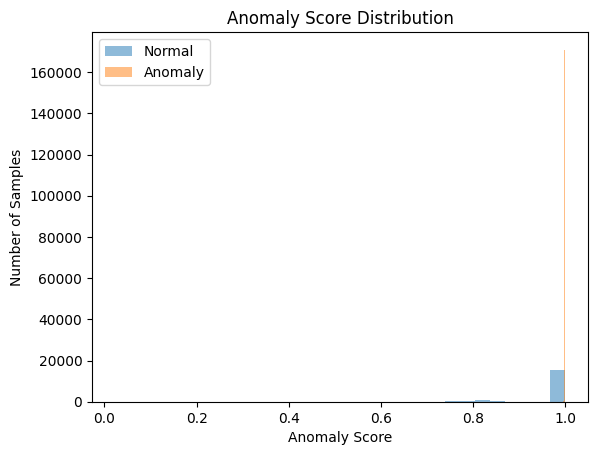

In [111]:
import matplotlib.pyplot as plt
# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()

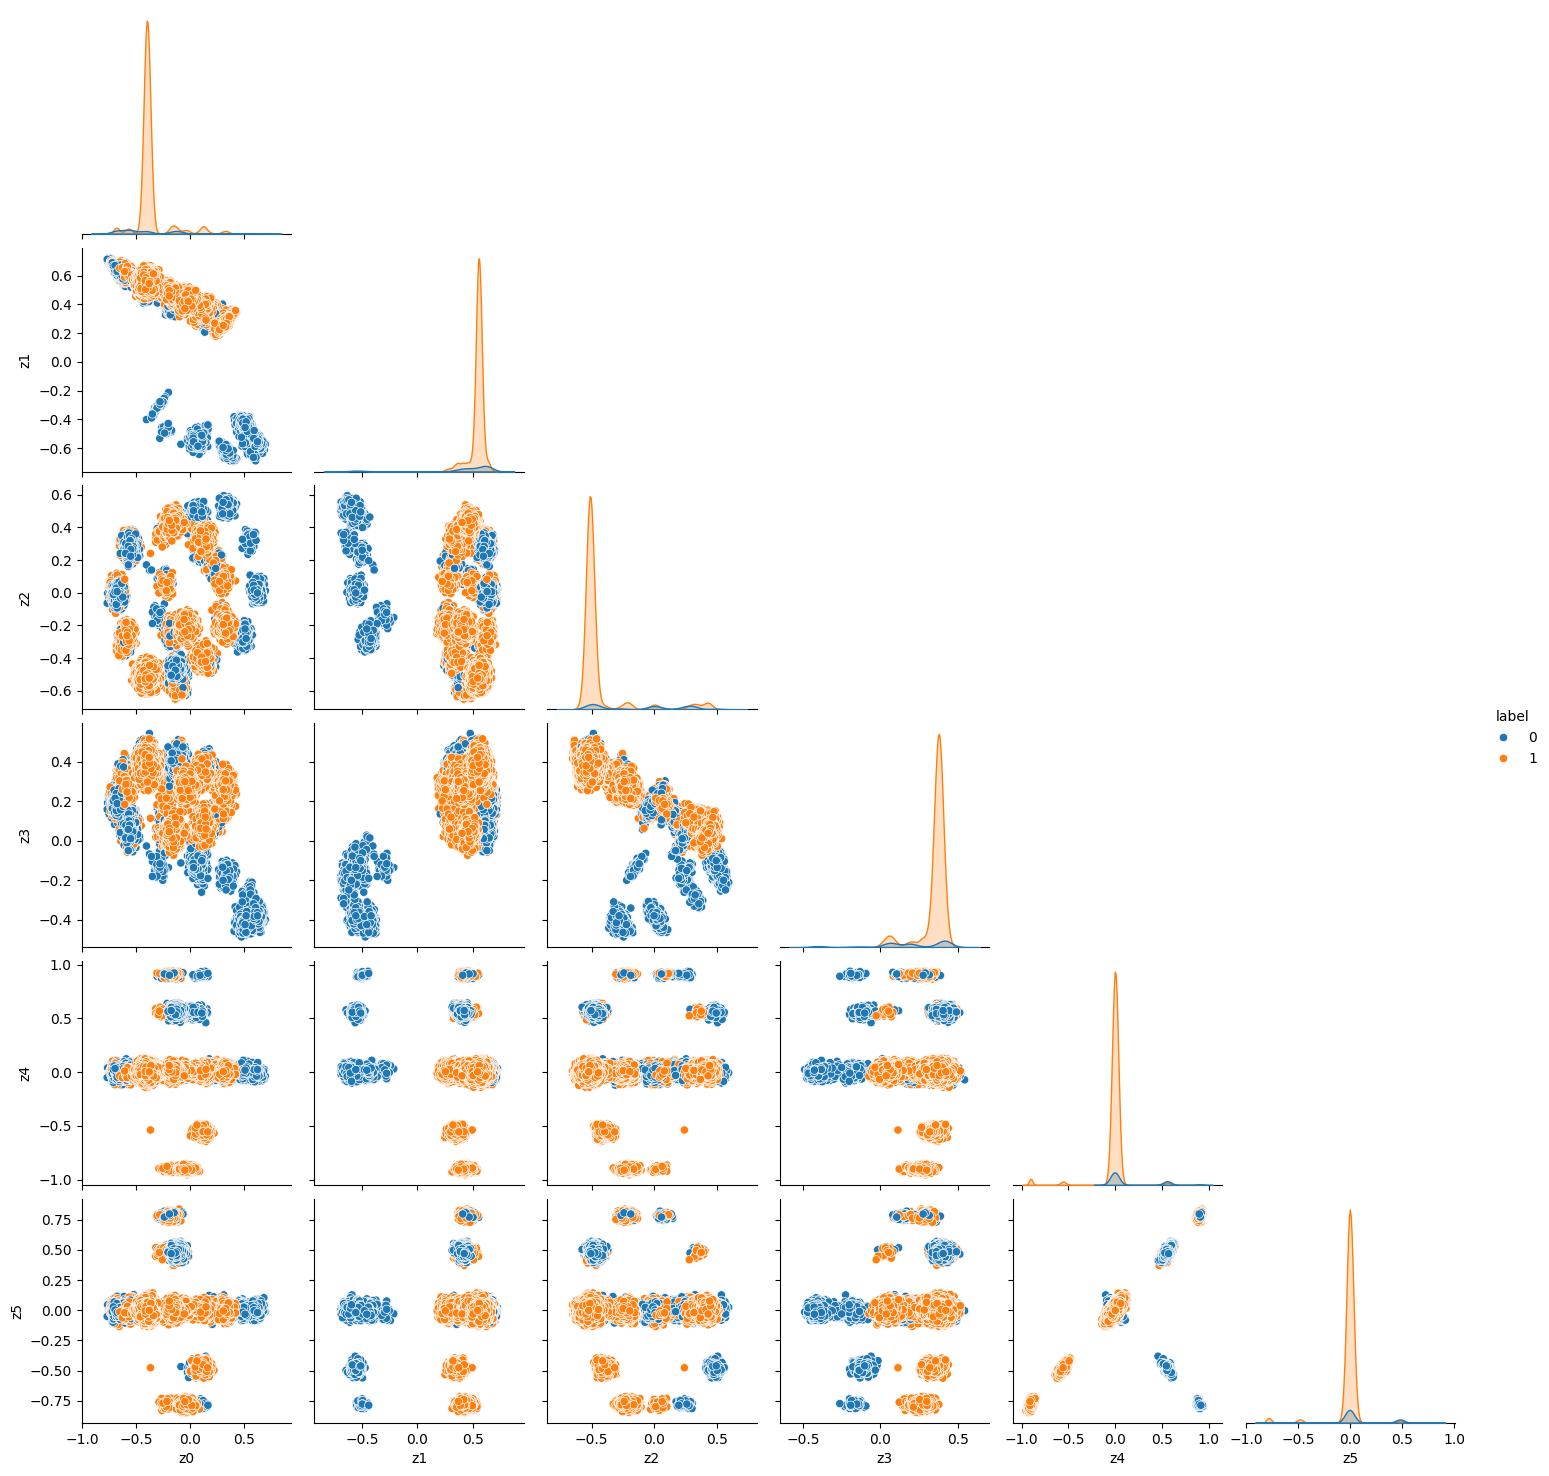

In [109]:
import pandas as pd
import seaborn as sns

latent_df = pd.DataFrame(latent_test, columns=[f"z{i}" for i in range(6)])
latent_df['label'] = y_true

sns.pairplot(latent_df, hue='label', diag_kind='kde', corner=True)
